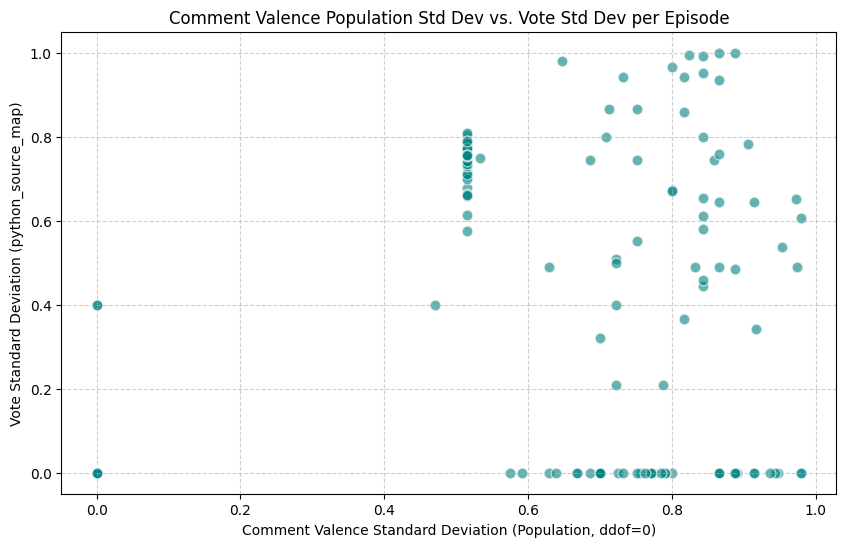

In [7]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pymongo import MongoClient

# 1. Connect to MongoDB
with open("config.json") as f:
    config = json.load(f)

client = MongoClient(config["mongo_uri"])
db = client["consensus"]

# 2. Fetch Vote Standard Deviation directly from python_source_map
episodes_cursor = db["python_source_map"].find(
    {}, {"Episode #": 1, "Standard Deviation": 1, "_id": 0}
)
episodes_df = pd.DataFrame(list(episodes_cursor))
episodes_df["vote_std"] = pd.to_numeric(
    episodes_df["Standard Deviation"], errors="coerce"
)

# 3. Fetch comments & calculate Population Standard Deviation of Valence (ddof=0)
comments_cursor = db["python_source_map_comments"].find(
    {}, {"Episode #": 1, "valence": 1, "manual_valence": 1, "_id": 0}
)
comments_df = pd.DataFrame(list(comments_cursor))

comments_df["active_valence"] = comments_df["manual_valence"].combine_first(
    comments_df["valence"]
)
comments_df["active_valence"] = pd.to_numeric(
    comments_df["active_valence"], errors="coerce"
)

# Exclude neutral/discussion comments (valence == 0)
clean_comments = comments_df[comments_df["active_valence"] != 0]


def calculate_valence_std_pop(x):
    if len(x) > 1:
        return np.std(x, ddof=0)
    elif len(x) == 1:
        return 0.0
    return np.nan


valence_stats = (
    clean_comments.groupby("Episode #")["active_valence"]
    .agg(valence_std=calculate_valence_std_pop)
    .reset_index()
)

# 4. Merge datasets
merged_df = pd.merge(
    valence_stats, episodes_df, on="Episode #", how="inner"
).dropna(subset=["valence_std", "vote_std"])

# 5. Generate Scatterplot
plt.figure(figsize=(10, 6))
plt.scatter(
    merged_df["valence_std"],
    merged_df["vote_std"],
    alpha=0.6,
    color="teal",
    edgecolors="w",
    s=60,
)
plt.title("Comment Valence Population Std Dev vs. Vote Std Dev per Episode")
plt.xlabel("Comment Valence Standard Deviation (Population, ddof=0)")
plt.ylabel("Vote Standard Deviation (python_source_map)")
plt.grid(True, linestyle="--", alpha=0.6)
plt.show()

In [6]:
import json
import numpy as np
import pandas as pd
from pymongo import MongoClient

# 1. Connect to MongoDB
with open("config.json") as f:
    config = json.load(f)

client = MongoClient(config["mongo_uri"])
db = client["consensus"]

# 2. Fetch Vote metrics from python_source_map
episodes_cursor = db["python_source_map"].find(
    {},
    {
        "Episode #": 1,
        "Standard Deviation": 1,
        "Yes Votes": 1,
        "No Votes": 1,
        "_id": 0,
    },
)
episodes_df = pd.DataFrame(list(episodes_cursor))
episodes_df["vote_std"] = pd.to_numeric(
    episodes_df["Standard Deviation"], errors="coerce"
)
episodes_df["Yes Votes"] = (
    pd.to_numeric(episodes_df["Yes Votes"], errors="coerce").fillna(0).astype(int)
)
episodes_df["No Votes"] = (
    pd.to_numeric(episodes_df["No Votes"], errors="coerce").fillna(0).astype(int)
)
episodes_df["total_votes"] = episodes_df["Yes Votes"] + episodes_df["No Votes"]
episodes_df["net_votes"] = episodes_df["Yes Votes"] - episodes_df["No Votes"]

# 3. Fetch comments & calculate Population Standard Deviation of Valence (ddof=0)
comments_cursor = db["python_source_map_comments"].find(
    {}, {"Episode #": 1, "valence": 1, "manual_valence": 1, "_id": 0}
)
comments_df = pd.DataFrame(list(comments_cursor))

comments_df["active_valence"] = comments_df["manual_valence"].combine_first(
    comments_df["valence"]
)
comments_df["active_valence"] = pd.to_numeric(
    comments_df["active_valence"], errors="coerce"
)

# Exclude neutral/discussion comments (active_valence == 0)
clean_comments = comments_df[comments_df["active_valence"] != 0]


def calculate_valence_std_pop(x):
    if len(x) > 1:
        return np.std(x, ddof=0)
    elif len(x) == 1:
        return 0.0
    return np.nan


valence_stats = (
    clean_comments.groupby("Episode #")["active_valence"]
    .agg(
        valence_std=calculate_valence_std_pop,
        valence_sum="sum",
        comment_count="count",
    )
    .reset_index()
)

# 4. Merge datasets
merged_df = pd.merge(valence_stats, episodes_df, on="Episode #", how="inner")

# Organize columns cleanly for Excel & Pivot Tables
export_df = merged_df[
    [
        "Episode #",
        "valence_std",
        "vote_std",
        "comment_count",
        "valence_sum",
        "Yes Votes",
        "No Votes",
        "total_votes",
        "net_votes",
    ]
].sort_values(by="Episode #")

# 5. Export to Excel
excel_filename = "episode_valence_vs_votes_analysis.xlsx"
export_df.to_excel(excel_filename, index=False, engine="openpyxl")

print(f"Successfully exported {len(export_df)} records to '{excel_filename}'.")

Successfully exported 129 records to 'episode_valence_vs_votes_analysis.xlsx'.
